# v2 — Meilleur modèle de détection d'URL de phishing

Ce notebook construit, évalue et explique le meilleur modèle trouvé pour classer une URL
en légitime (0) ou phishing (1), et lui donner un score de risque de 1 à 10.

**Démarche.** Une soixantaine de variantes ont été comparées en validation croisée sur le
seul jeu d'entraînement (le journal complet est en section 5). Le test n'est utilisé qu'une
fois, à la fin (section 7). Toutes les transformations sont dans des `Pipeline` scikit-learn,
ajustées uniquement sur les plis d'entraînement.

**Modèle retenu.** Vote souple de trois boostings optimisés (LightGBM, XGBoost, CatBoost)
sur trois blocs de variables :

1. les 81 variables non constantes du jeu de données (URL, contenu de la page, externes) ;
2. 70 variables lexicales supplémentaires calculées sur l'URL (`phishing.url_text`) ;
3. la probabilité donnée par une régression logistique sur les n-grammes de caractères de
   l'URL (TF-IDF), calculée hors-pli pour ne pas fuiter.

**Point de vigilance : la fuite par domaine.** Près de la moitié des URL de validation et
de test ont un domaine déjà vu à l'entraînement, et un domaine porte presque toujours une
seule étiquette. Les scores sur le découpage aléatoire du projet sont donc optimistes.
Chaque modèle est aussi évalué avec des plis qui ne partagent aucun domaine
(`StratifiedGroupKFold`), ce qui mesure mieux la détection sur un site inconnu.

## 1. Imports et paramètres

In [1]:
import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from phishing import config, phishtank
from phishing.data import clean, feature_groups, load_raw, load_split, save_splits, split
from phishing.evaluation import (
    classification_metrics,
    plot_calibration,
    plot_confusion_matrix,
    risk_level_table,
    save_metrics,
)
from phishing.features import extract
from phishing.url_text import ExtraFeatures, OutOfFoldProba, char_tfidf_model, registered_domain

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_colwidth", 90)

URL, TARGET = config.URL_COL, config.TARGET_COL
SEED = config.RANDOM_STATE
N_JOBS = 4

# La comparaison de la section 4 prend une quinzaine de minutes : False pour la sauter.
RUN_BENCHMARK = True

## 2. Données

Les découpages train / validation / test (70 / 15 / 15, stratifiés) sont ceux de
`scripts/make_splits.py`. On les recrée s'ils manquent. Les variables constantes sur le
train sont retirées.

In [2]:
if not (config.PROCESSED_DIR / "train.csv").exists():
    save_splits(split(clean(load_raw())))

train, val, test = (load_split(name) for name in ("train", "val", "test"))
groups = feature_groups(list(train.columns))
constant = [c for cols in groups.values() for c in cols if train[c].nunique() == 1]
FEATURES = [c for cols in groups.values() for c in cols if c not in constant]
# Variables recalculables sur une URL seule (écrites par scripts/check_features.py)
portable_file = config.PROCESSED_DIR / "portable_features.json"
PORTABLE = None
if portable_file.exists():
    PORTABLE = [c for c in json.loads(portable_file.read_text()) if c in FEATURES]

for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:>5} : {len(part):>5} URL, {part[TARGET].mean():.1%} de phishing")
print(f"{len(FEATURES)} variables gardées, constantes retirées : {constant}")

train :  7999 URL, 50.0% de phishing
  val :  1715 URL, 50.0% de phishing
 test :  1715 URL, 50.0% de phishing
81 variables gardées, constantes retirées : ['nb_or', 'ratio_nullHyperlinks', 'ratio_intRedirection', 'ratio_intErrors', 'submit_email', 'sfh']


## 3. La fuite par domaine

On regroupe les URL par domaine enregistré (`paypal.com` pour `https://www.paypal.com/fr`).

In [3]:
for part in (train, val, test):
    part["domain"] = part[URL].map(registered_domain)

seen = set(train["domain"])
for name, part in [("val", val), ("test", test)]:
    share = part["domain"].isin(seen).mean()
    print(f"{name} : {share:.1%} des URL ont un domaine présent dans le train")

per_domain = train.groupby("domain")[TARGET].agg(["size", "mean"])
multi = per_domain[per_domain["size"] > 1]
pure = ((multi["mean"] == 0) | (multi["mean"] == 1)).mean()
print(f"{len(multi)} domaines ont plusieurs URL dans le train ; {pure:.1%} n'ont qu'une étiquette")
display(per_domain.sort_values("size", ascending=False).head(8))

val : 47.9% des URL ont un domaine présent dans le train
test : 48.6% des URL ont un domaine présent dans le train
686 domaines ont plusieurs URL dans le train ; 96.9% n'ont qu'une étiquette


,size,mean
domain,,
blogspot.com,258,0.662791
duilawyeryork.com,248,1.000000
appspot.com,191,1.000000
wikipedia.org,118,0.000000
google.com,103,0.844660
tumblr.com,66,0.151515
sharepoint.com,56,1.000000
000webhostapp.com,44,1.000000


Un modèle qui reconnaît un domaine déjà vu est récompensé sur le découpage aléatoire, sans
savoir détecter un site nouveau. D'où les deux mesures de la section 4 : plis aléatoires
(comme le test du projet) et plis par domaine (site inconnu).

## 4. Comparaison des approches

In [4]:
CV_RANDOM = StratifiedKFold(config.CV_FOLDS, shuffle=True, random_state=SEED)
CV_DOMAIN = StratifiedGroupKFold(config.CV_FOLDS, shuffle=True, random_state=SEED)


def out_of_fold(model, X, y, cv, groups=None):
    """Probabilités hors-pli : chaque URL est prédite par un modèle qui ne l'a pas vue."""
    proba = np.zeros(len(y))
    for fit_idx, pred_idx in cv.split(X, y, groups):
        fitted = clone(model).fit(X.iloc[fit_idx], y[fit_idx])
        proba[pred_idx] = fitted.predict_proba(X.iloc[pred_idx])[:, 1]
    return proba


def summary(y, proba):
    m = classification_metrics(y, (proba >= 0.5).astype(int), proba)
    m["log_loss"] = log_loss(y, np.clip(proba, 1e-6, 1 - 1e-6))
    return {
        k: m[k] for k in ("accuracy", "f1", "false_positive_rate", "roc_auc", "brier", "log_loss")
    }

**Blocs de variables.** `features()` assemble les colonnes du jeu de données, les variables
lexicales supplémentaires et la probabilité TF-IDF hors-pli. Les hyperparamètres des trois
boostings viennent d'une recherche Optuna (≈ 260 essais, 20 min par modèle, log loss en
validation croisée sur le train).

In [5]:
def features(base=FEATURES, extra=True, tfidf=True):
    parts = [("base", "passthrough", list(base))]
    if extra:
        parts.append(("extra", ExtraFeatures(), [URL]))
    if tfidf:
        # by_domain=True : plis internes sans domaine commun
        parts.append(("tfidf", OutOfFoldProba(char_tfidf_model(), by_domain=True), [URL]))
    return ColumnTransformer(parts)


LGBM_PARAMS = dict(
    n_estimators=721,
    learning_rate=0.0199,
    num_leaves=71,
    min_child_samples=8,
    subsample=0.66,
    subsample_freq=1,
    colsample_bytree=0.25,
    reg_lambda=1.26,
    reg_alpha=0.0028,
)
XGB_PARAMS = dict(
    n_estimators=1956,
    learning_rate=0.0063,
    max_depth=10,
    min_child_weight=0.61,
    subsample=0.52,
    colsample_bytree=0.26,
    gamma=0.21,
    reg_lambda=0.135,
    tree_method="hist",
)
CAT_PARAMS = dict(
    iterations=837,
    learning_rate=0.0617,
    depth=6,
    l2_leaf_reg=3.13,
    random_strength=1.88,
    bagging_temperature=1.26,
)


def lgbm(**kw):
    return LGBMClassifier(**{**LGBM_PARAMS, **kw}, verbose=-1, n_jobs=N_JOBS, random_state=SEED)


def ensemble():
    return VotingClassifier(
        [
            ("lgbm", lgbm()),
            ("xgb", XGBClassifier(**XGB_PARAMS, n_jobs=N_JOBS, random_state=SEED)),
            (
                "cat",
                CatBoostClassifier(**CAT_PARAMS, verbose=0, thread_count=N_JOBS, random_seed=SEED),
            ),
        ],
        voting="soft",
    )


def final_model(base=FEATURES):
    return make_pipeline(features(base), ensemble())

In [6]:
default_lgbm = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.03,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.7,
    verbose=-1,
    n_jobs=N_JOBS,
    random_state=SEED,
)
CANDIDATES = {
    "Régression logistique": make_pipeline(
        features(extra=False, tfidf=False), StandardScaler(), LogisticRegression(max_iter=3000)
    ),
    "Forêt aléatoire": make_pipeline(
        features(extra=False, tfidf=False),
        RandomForestClassifier(500, n_jobs=N_JOBS, random_state=SEED),
    ),
    "TF-IDF de l'URL seul": char_tfidf_model(),
    "LightGBM": make_pipeline(features(extra=False, tfidf=False), default_lgbm),
    "LightGBM + variables URL": make_pipeline(features(tfidf=False), default_lgbm),
    "LightGBM + variables URL + TF-IDF": make_pipeline(features(), default_lgbm),
    "Modèle final (vote de 3)": final_model(),
}

X_train, y_train = train[FEATURES + [URL]], train[TARGET].to_numpy()
rows = []
if RUN_BENCHMARK:
    for name, model in CANDIDATES.items():
        start = time.time()
        for cv_name, cv, grp in [
            ("aléatoire", CV_RANDOM, None),
            ("par domaine", CV_DOMAIN, train["domain"]),
        ]:
            proba = out_of_fold(model, X_train, y_train, cv, grp)
            rows.append({"modèle": name, "plis": cv_name, **summary(y_train, proba)})
        print(f"{name} : {time.time() - start:.0f} s")
    benchmark = pd.DataFrame(rows)
    display(
        benchmark.pivot(index="modèle", columns="plis", values=["accuracy", "roc_auc", "brier"])
        .reindex(list(CANDIDATES))
        .round(4)
    )

Régression logistique : 7 s


Forêt aléatoire : 19 s


TF-IDF de l'URL seul : 40 s


LightGBM : 12 s


LightGBM + variables URL : 24 s


LightGBM + variables URL + TF-IDF : 227 s


Modèle final (vote de 3) : 333 s


accuracy               roc_auc              \
plis                              aléatoire par domaine aléatoire par domaine   
modèle                                                                          
Régression logistique                0.9431      0.9330    0.9852      0.9802   
Forêt aléatoire                      0.9660      0.9489    0.9934      0.9864   
TF-IDF de l'URL seul                 0.9300      0.9069    0.9813      0.9686   
LightGBM                             0.9712      0.9512    0.9943      0.9888   
LightGBM + variables URL             0.9716      0.9561    0.9945      0.9893   
LightGBM + variables URL + TF-IDF    0.9771      0.9645    0.9963      0.9933   
Modèle final (vote de 3)             0.9774      0.9671    0.9963      0.9934   

                                      brier              
plis                              aléatoire par domaine  
modèle                                                   
Régression logistique                0.0426      0.0496  
Forêt aléatoire                      0.0325      0.0489  
TF-IDF de l'URL seul                 0.0518      0.0692  
LightGBM                             0.0245      0.0380  
LightGBM + variables URL             0.0228      0.0356  
LightGBM + variables URL + TF-IDF    0.0194      0.0279  
Modèle final (vote de 3)             0.0184      0.0264

**Lecture.** Les variables externes (indexation Google, PageRank, trafic, âge du domaine)
portent l'essentiel du signal. Les variables URL ajoutées et surtout la probabilité TF-IDF
apportent +0,6 point d'exactitude en plis aléatoires et +1,3 point en plis par domaine : le
gain tient sur des sites inconnus, ce n'est pas de la mémorisation de domaines. Le vote réduit surtout le score de Brier, utile pour le
score de risque.

## 5. Journal des essais

Toutes les lignes sont mesurées de la même façon : validation croisée à 5 plis sur le
train seul (3 répétitions pour les trois dernières lignes), puis modèle entraîné sur le train
et évalué sur la validation. « Par domaine » : plis sans domaine commun. « 81 var. du jeu » :
les 87 variables du jeu moins les 6 constantes. « Ajoutées » : les 70 variables de
`phishing.url_text`. Les hyperparamètres « optimisés » viennent d'Optuna (log loss en
validation croisée sur le train).

| Modèle | Variables | Exactitude CV | AUC CV | Brier CV | Exactitude CV par domaine | Exactitude validation |
|---|---|---|---|---|---|---|
| Classe majoritaire | 81 var. du jeu | 50,01 % | 0,4999 | 0,2500 |  | 49,97 % |
| Naive Bayes gaussien | 81 var. du jeu | 64,85 % | 0,6585 | 0,3508 |  | 65,25 % |
| Arbre de décision | 81 var. du jeu | 92,96 % | 0,9611 | 0,0565 |  | 94,75 % |
| k plus proches voisins (k=15) | 81 var. du jeu | 93,32 % | 0,9805 | 0,0502 |  | 94,46 % |
| Régression logistique | 81 var. du jeu | 94,31 % | 0,9852 | 0,0426 |  | 95,34 % |
| Perceptron multicouche (128, 64) | 81 var. du jeu | 95,54 % | 0,9887 | 0,0346 |  | 96,21 % |
| SVM à noyau RBF | 81 var. du jeu | 95,80 % | 0,9894 | 0,0323 |  | 96,21 % |
| ExtraTrees | 81 var. du jeu | 96,37 % | 0,9935 | 0,0324 |  | 96,97 % |
| Forêt aléatoire | 81 var. du jeu | 96,60 % | 0,9934 | 0,0325 |  | 96,73 % |
| CatBoost | 81 var. du jeu | 96,64 % | 0,9935 | 0,0260 |  | 97,32 % |
| HistGradientBoosting | 81 var. du jeu | 96,72 % | 0,9934 | 0,0265 |  | 97,38 % |
| XGBoost | 81 var. du jeu | 96,84 % | 0,9938 | 0,0254 |  | 97,14 % |
| LightGBM | 81 var. du jeu | 97,12 % | 0,9943 | 0,0245 | 95,12 % | 97,38 % |
| LightGBM | 26 var. recalculables depuis l'URL | 86,79 % | 0,9447 | 0,0938 |  | 85,83 % |
| LightGBM | variables URL | 91,36 % | 0,9711 | 0,0642 |  | 91,72 % |
| LightGBM | URL + contenu | 94,29 % | 0,9850 | 0,0432 |  | 94,58 % |
| LightGBM | contenu + externes | 95,00 % | 0,9871 | 0,0393 |  | 95,45 % |
| LightGBM | URL + externes | 96,94 % | 0,9932 | 0,0258 |  | 97,08 % |
| TF-IDF mots + rég. log. | URL brute | 92,24 % | 0,9706 | 0,0614 |  | 93,12 % |
| TF-IDF caractères 2-6 + rég. log. | URL brute | 92,85 % | 0,9804 | 0,0533 |  | 93,88 % |
| TF-IDF caractères 1-5 + rég. log. | URL brute | 93,00 % | 0,9813 | 0,0518 |  | 94,29 % |
| TF-IDF caractères + mots | URL brute | 94,05 % | 0,9830 | 0,0459 | 91,01 % | 94,58 % |
| SVM linéaire calibré, TF-IDF | URL brute | 94,14 % | 0,9825 | 0,0458 | 91,04 % | 94,40 % |
| TF-IDF hôte / chemin / mots | URL brute | 94,36 % | 0,9849 | 0,0429 | 91,04 % | 94,93 % |
| LightGBM | recalculables + 70 var. ajoutées | 92,09 % | 0,9752 | 0,0586 |  | 92,48 % |
| LightGBM optimisé | recalculables + ajoutées + TF-IDF (URL seule) | 94,62 % | 0,9873 | 0,0399 | 92,39 % | 95,51 % |
| LightGBM | 81 + 70 var. ajoutées | 97,16 % | 0,9945 | 0,0228 | 95,61 % | 97,38 % |
| CatBoost | 81 + 70 var. ajoutées | 96,84 % | 0,9938 | 0,0248 |  | 97,49 % |
| LightGBM | 81 + TF-IDF empilé | 97,47 % | 0,9963 | 0,0203 |  | 97,84 % |
| LightGBM | 81 + ajoutées + TF-IDF (plis internes aléatoires) | 97,61 % | 0,9963 | 0,0198 | 96,46 % | 98,02 % |
| LightGBM | 81 + ajoutées + TF-IDF (plis internes par domaine) | 97,71 % | 0,9963 | 0,0194 | 96,45 % | 97,96 % |
| LightGBM | 81 + ajoutées + TF-IDF hôte/chemin | 97,69 % | 0,9960 | 0,0197 | 96,12 % | 98,02 % |
| LightGBM optimisé | + encodage cible du domaine | 97,65 % | 0,9963 | 0,0185 | 96,66 % | 97,73 % |
| CatBoost optimisé | 81 + ajoutées + TF-IDF | 97,52 % | 0,9961 | 0,0196 |  | 97,67 % |
| XGBoost optimisé | 81 + ajoutées + TF-IDF | 97,70 % | 0,9962 | 0,0185 |  | 97,84 % |
| LightGBM optimisé | 81 + ajoutées + TF-IDF | 97,67 % | 0,9962 | 0,0187 |  | 97,90 % |
| Empilement (rég. log. sur 4 modèles) | 81 + ajoutées + TF-IDF | 97,81 % | 0,9958 | 0,0185 |  | 97,78 % |
| Vote LightGBM + XGBoost + CatBoost + ExtraTrees | 81 + ajoutées + TF-IDF | 97,73 % | 0,9963 | 0,0183 | 96,76 % | 97,61 % |
| **Vote LightGBM + XGBoost + CatBoost (retenu)** | 81 + ajoutées + TF-IDF | 97,73 % | 0,9963 | 0,0183 | 96,76 % | 97,73 % |

Ce qui ressort :

- les boostings dominent dès le départ ; la régression logistique est près de 3 points derrière ;
- ajouter les 7 variables externes aux variables d'URL fait passer LightGBM de 91,4 % à 96,9 % ;
- l'ajout qui compte le plus est la probabilité TF-IDF empilée (+0,5 point en plis
  aléatoires, +0,8 point en plis par domaine, par rapport aux 81 + 70 variables) ;
- l'optimisation des hyperparamètres et les ensembles gagnent surtout en Brier ;
- l'encodage cible du domaine n'apporte rien de plus que le TF-IDF : on ne le garde pas ;
- au-delà de 97,7 %, les écarts sont dans le bruit (environ ±0,2 point entre répétitions).

## 6. Contrôle sur la validation

Le modèle final est entraîné sur le train et évalué sur la validation, qui n'a servi à
aucun choix d'hyperparamètre.

In [7]:
X_val, y_val = val[FEATURES + [URL]], val[TARGET].to_numpy()
start = time.time()
model = final_model().fit(X_train, y_train)
p_val = model.predict_proba(X_val)[:, 1]
print(f"entraînement + prédiction : {time.time() - start:.0f} s")

unseen_val = ~val["domain"].isin(seen).to_numpy()
display(
    pd.DataFrame(
        {
            "validation": summary(y_val, p_val),
            "domaines inconnus": summary(y_val[unseen_val], p_val[unseen_val]),
        }
    ).T.round(4)
)
display(risk_level_table(y_val, p_val))

entraînement + prédiction : 41 s


,accuracy,f1,false_positive_rate,roc_auc,brier,log_loss
validation,0.9778,0.9778,0.0186,0.9979,0.0166,0.0584
domaines inconnus,0.9620,0.9472,0.0229,0.9944,0.0276,0.0925


,n_urls,phishing_rate
level,,
low,856,0.021028
medium,15,0.466667
high,844,0.985782


## 7. Évaluation finale sur le test (une seule fois)

Le modèle est réentraîné sur train + validation, puis évalué sur le test.

In [8]:
train_val = pd.concat([train, val], ignore_index=True)
X_tv, y_tv = train_val[FEATURES + [URL]], train_val[TARGET].to_numpy()
X_test, y_test = test[FEATURES + [URL]], test[TARGET].to_numpy()

final = final_model().fit(X_tv, y_tv)
p_test = final.predict_proba(X_test)[:, 1]
y_pred = (p_test >= 0.5).astype(int)

test_metrics = classification_metrics(y_test, y_pred, p_test)
save_metrics(test_metrics, config.REPORTS_DIR / "v2_test_metrics.json")

seen_tv = set(train_val["domain"])
unseen_test = ~test["domain"].isin(seen_tv).to_numpy()
display(
    pd.DataFrame(
        {
            "test": summary(y_test, p_test),
            f"domaine vu ({(~unseen_test).sum()} URL)": summary(
                y_test[~unseen_test], p_test[~unseen_test]
            ),
            f"domaine inconnu ({unseen_test.sum()} URL)": summary(
                y_test[unseen_test], p_test[unseen_test]
            ),
        }
    ).T.round(4)
)
print({k: test_metrics[k] for k in ("tp", "fp", "tn", "fn")})

,accuracy,f1,false_positive_rate,roc_auc,brier,log_loss
test,0.9784,0.9783,0.0186,0.9986,0.0152,0.0506
domaine vu (863 URL),0.9942,0.9953,0.0060,0.9997,0.0050,0.0192
domaine inconnu (852 URL),0.9624,0.9511,0.0268,0.9958,0.0257,0.0823


{'tp': 836, 'fp': 16, 'tn': 842, 'fn': 21}


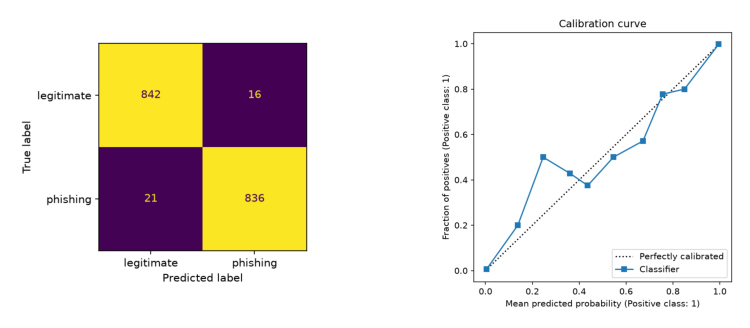

In [9]:
plot_confusion_matrix(y_test, y_pred, config.FIGURES_DIR / "v2_confusion_matrix.png")
plot_calibration(y_test, p_test, config.FIGURES_DIR / "v2_calibration.png")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, image in zip(axes, ["v2_confusion_matrix.png", "v2_calibration.png"], strict=True):
    ax.imshow(plt.imread(config.FIGURES_DIR / image))
    ax.axis("off")
plt.show()

**Score de risque.** `risk = 1 + 9 × P(phishing)`. Avec un score fiable, le taux de phishing
réel monte nettement d'un niveau à l'autre.

In [10]:
display(risk_level_table(y_test, p_test))

,n_urls,phishing_rate
level,,
low,850,0.018824
medium,27,0.444444
high,838,0.989260


## 8. Ce que le modèle regarde

Importance (gain) des variables dans le LightGBM du vote. `oof_proba` est la probabilité
TF-IDF, `x_*` les variables lexicales ajoutées.

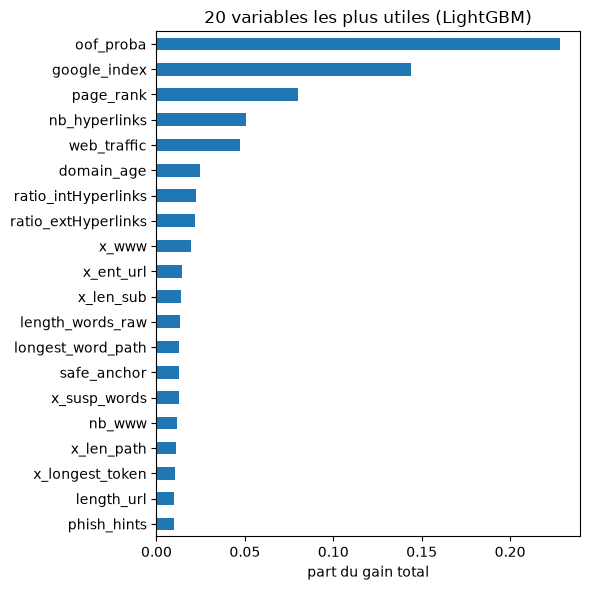

In [11]:
names = final[0].get_feature_names_out()
names = [n.split("__", 1)[1] for n in names]
booster = final[-1].named_estimators_["lgbm"].booster_
importance = pd.Series(booster.feature_importance("gain"), index=names).sort_values()
importance = importance / importance.sum()

fig, ax = plt.subplots(figsize=(6, 6))
importance.tail(20).plot.barh(ax=ax)
ax.set_xlabel("part du gain total")
ax.set_title("20 variables les plus utiles (LightGBM)")
fig.tight_layout()
plt.show()

## 9. Analyse des erreurs du test

In [12]:
errors = test.assign(p_phishing=p_test, risk=1 + 9 * p_test)[y_pred != y_test]
cols = [URL, TARGET, "risk", "google_index", "page_rank", "web_traffic", "domain_age"]
print(f"{len(errors)} erreurs sur {len(test)} URL")
print("Phishing manqués (faux négatifs) :")
display(errors[errors[TARGET] == 1].sort_values("risk")[cols].head(10))
print("Sites légitimes signalés (faux positifs) :")
display(errors[errors[TARGET] == 0].sort_values("risk", ascending=False)[cols].head(10))

37 erreurs sur 1715 URL
Phishing manqués (faux négatifs) :


,url,status,risk,google_index,page_rank,web_traffic,domain_age
851,http://music.eanswers.com/music.eanswers.com/go/,1,1.246974,1,4,12091,7928
1230,https://www.coalesceresearchgroup.com/conferences/foodscience/programschedule,1,1.261890,0,3,796025,581
921,http://www.ciclismo-online.it/ma/,1,1.421768,0,2,0,6392
393,http://www.imcreator.com/viewer/vbid-fa0f29d5-fpsjmms8,1,1.488889,1,5,52251,3708
325,https://feceboolk.blogspot.com/,1,1.694772,0,5,0,7309
488,https://www.zipsurvey.com/Survey.aspx?suid=85067,1,1.753056,0,3,4053232,6490
629,http://www.icebrrg.com/Public/EmbedForm.aspx?formID=107217,1,2.066060,0,4,0,5071
1559,http://the-invisible-man-movie-2020.over-blog.com/,1,2.295436,0,5,0,5992
302,https://littlehaygolf.co.uk/azmedien/,1,2.424467,0,2,1699634,1716
279,http://loveslife.biz/,1,2.482451,0,2,1264301,3000


Sites légitimes signalés (faux positifs) :


,url,status,risk,google_index,page_rank,web_traffic,domain_age
1393,https://accounts.google.com/ServiceLogin?service=blogger&hl=pt_BR&passive=true&continu...,0,9.888880,0,10,1,8348
1361,http://time-ticket.blogspot.com/,0,9.132553,1,5,0,7298
96,http://silhouettesfree.com/s.php?silhouette=Mickey+Mouse,0,8.473245,0,2,2597330,2595
1396,https://swap.gg/r/h1z1swap,0,8.265415,1,4,114006,-1
385,http://dick-of.cubehost.ru/archive/2015/1.php?n=25&id=128520,0,8.257428,1,0,4219048,1408
1653,https://www.miairsoft.org/index.php?PHPSESSID=bdf0358a8eef04e44dc5ad4d41be389d;wwwRedi...,0,8.099661,0,2,6417540,1963
1444,http://www.thedigitallandscaping.com/classroom/,0,7.883871,1,1,0,-1
1194,https://gidfermer.com:443/,0,7.197381,1,2,377916,1448
1269,http://www.ectraining.com.hk/B885/b885tc.doc,0,7.015674,0,0,6482502,-1
1247,http://hardware-store-vashon.downloads.filetransit.com/,0,6.881584,1,4,178077,8181


Une bonne partie des erreurs restantes ressemble à du bruit d'étiquetage (grands sites
connus étiquetés phishing, pages d'authentification sur hébergeur gratuit étiquetées
légitimes) : on approche le plafond de ce jeu de données.

## 10. Modèle « URL seule » et PhishTank

Le modèle final a besoin de la page et de services externes (WHOIS, Google, trafic). Pour
juger une URL sans la visiter, on entraîne la même chaîne sur les seules variables
recalculables depuis l'URL (`portable_features.json`, voir `scripts/check_features.py`),
puis on mesure le rappel sur les URL de phishing récentes de PhishTank.

In [13]:
if PORTABLE is None:  # sans check_features.py : toutes nos variables lexicales
    PORTABLE = [c for c in extract(pd.Series(["http://a.com"])).columns if c in FEATURES]
url_only = make_pipeline(features(PORTABLE), lgbm()).fit(train_val[PORTABLE + [URL]], y_tv)
p_url = url_only.predict_proba(test[PORTABLE + [URL]])[:, 1]
display(
    pd.DataFrame(
        {
            "URL seule, test": summary(y_test, p_url),
            "URL seule, domaine inconnu": summary(y_test[unseen_test], p_url[unseen_test]),
        }
    ).T.round(4)
)

,accuracy,f1,false_positive_rate,roc_auc,brier,log_loss
"URL seule, test",0.9586,0.9583,0.0338,0.9931,0.0311,0.1071
"URL seule, domaine inconnu",0.9249,0.9012,0.0516,0.9795,0.0546,0.1806


In [14]:
if config.PHISHTANK_FILE.exists():
    pt = phishtank.load(config.PHISHTANK_FILE)
    X_pt = extract(pt[URL])[PORTABLE].assign(**{URL: pt[URL]})
    p_pt = url_only.predict_proba(X_pt)[:, 1]
    print(
        f"PhishTank : {len(pt)} URL de phishing, soumises du "
        f"{pt['submission_time'].min():%Y-%m-%d} au {pt['submission_time'].max():%Y-%m-%d}"
    )
    print(f"rappel au seuil 0,5 : {(p_pt >= 0.5).mean():.1%}")
    display(risk_level_table(np.ones(len(p_pt), dtype=int), p_pt))
else:
    print("PhishTank absent, voir scripts/fetch_phishtank.py")

PhishTank : 45741 URL de phishing, soumises du 2012-06-14 au 2026-11-13
rappel au seuil 0,5 : 93.0%


,n_urls,phishing_rate
level,,
low,2255,1.0
medium,1972,1.0
high,41514,1.0


## 11. Conclusion

| Évaluation (test, utilisé une seule fois) | URL | Exactitude | F1 | Faux positifs | ROC-AUC | Brier |
|---|---|---|---|---|---|---|
| Modèle final, test complet | 1 715 | 97,84 % | 0,978 | 1,9 % | 0,9986 | 0,0152 |
| Modèle final, domaine déjà vu | 863 | 99,42 % | 0,995 | 0,6 % | 0,9997 | 0,0050 |
| Modèle final, domaine inconnu | 852 | 96,24 % | 0,951 | 2,7 % | 0,9958 | 0,0257 |
| Modèle « URL seule », test complet | 1 715 | 95,86 % | 0,958 | 3,4 % | 0,9931 | 0,0311 |
| Modèle « URL seule », domaine inconnu | 852 | 92,49 % | 0,901 | 5,2 % | 0,9795 | 0,0546 |

- **Modèle retenu** : vote souple LightGBM + XGBoost + CatBoost sur les 81 variables du
  jeu, 70 variables lexicales ajoutées et la probabilité TF-IDF hors-pli. 37 erreurs sur
  1 715 URL (16 faux positifs, 21 faux négatifs). Les résultats du test sont cohérents avec
  la validation croisée (97,7 %) et la validation (97,8 %) : pas de sur-apprentissage du
  choix de modèle.
- **Score de risque** : il est bien calibré sans étape supplémentaire. Sur le test, 1,9 %
  de phishing en risque faible, 44 % en moyen, 98,9 % en élevé.
- **Ce qui compte** : la probabilité TF-IDF de l'URL, puis l'indexation Google, le
  PageRank, le nombre de liens et le trafic.
- **Limites** :
  - la moitié du test partage un domaine avec l'entraînement ; sur un domaine inconnu,
    il faut compter 96,2 % plutôt que 97,8 % ;
  - le modèle final a besoin de la page et de services externes (WHOIS, index Google,
    trafic) au moment de la prédiction ;
  - le jeu date de 2020. Sur les 45 741 URL de PhishTank, surtout récentes, le modèle
    « URL seule » en détecte 93,0 % au seuil 0,5, et 4,9 % restent en risque faible.
- **Pistes** :
  - revoir les étiquettes douteuses repérées en section 9 ;
  - ajouter des URL légitimes récentes, pour mesurer aussi les faux positifs du modèle
    « URL seule » hors du jeu de 2020.